# Этап 2. Аудит и подготовка данных

**Датасет:** Students Performance in Exams (Kaggle, автор spscientist)

**Ссылка:** https://www.kaggle.com/datasets/spscientist/students-performance-in-exams

**Цель этапа:** проверить структуру и значения данных по заданным критериям, оценить, насколько данные пригодны для задачи из Этапа 1 (связь факторов с оценкой по математике), и подготовить чистую версию таблицы для анализа.

**План аудита:**
1. Фиксация исходных данных
2. Характеристика признаков (смысл, тип, правило)
3. Типы данных
4. Пропуски
5. Дубликаты
6. Категориальные значения (формат, регистр, пробелы)
7. Диапазоны, выбросы и аномалии
8. Согласованность
9. Баланс классов целевой переменной
10. Профиль качества
11. Приоритеты и решение по данным
12. Подготовка данных и сохранение результата
13. Вывод

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Фиксация исходных данных

Сначала фиксируем, с какой версией данных работаем: файл, число строк и столбцов. Исходный файл дальше не меняем - все исправления сохраняем в отдельный файл.

Файл скачан с Kaggle. Важный момент: после открытия в Excel файл был пересохранён с разделителем `;` вместо `,` (оригинал на Kaggle - через запятую). Поэтому используем `sep=None` - pandas сам определяет разделитель, и код работает с обоими вариантами файла.

In [2]:
RAW_PATH = '../data/raw/StudentsPerformance.csv'
RAW_URL = 'https://raw.githubusercontent.com/arsenijchekin-a11y/icp-students-performance/main/data/raw/StudentsPerformance.csv'

# если ноутбук запущен из папки репозитория - берём локальный файл, иначе (например, в Colab) - с GitHub
if os.path.exists(RAW_PATH):
    source = RAW_PATH
else:
    source = RAW_URL

df_raw = pd.read_csv(source, sep=None, engine='python')

print('Строк:', df_raw.shape[0])
print('Столбцов:', df_raw.shape[1])
df_raw.head()

Строк: 1000
Столбцов: 8


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 2. Характеристика признаков

До проверок определяем смысл строки, ключ, типы и правила для каждого поля.

**Строка** - один учащийся и его результаты по трём экзаменам.

**Ключ:** в датасете нет идентификатора ученика (ID). Это значит, что две одинаковые строки могут быть как дублем, так и двумя разными учениками с одинаковыми данными - это учитываем при проверке дубликатов.

In [3]:
features = pd.DataFrame({
    'Поле': ['gender', 'race/ethnicity', 'parental level of education', 'lunch',
             'test preparation course', 'math score', 'reading score', 'writing score'],
    'Смысл': ['Пол', 'Этническая группа (анонимно)', 'Образование родителей', 'Тип питания в школе',
              'Курс подготовки к экзамену', 'Оценка по математике', 'Оценка по чтению', 'Оценка по письму'],
    'Тип данных': ['Категория', 'Категория', 'Категория (порядковая)', 'Категория',
                   'Категория', 'Целое число', 'Целое число', 'Целое число'],
    'Правило': ['female / male, обязательное', 'group A-E, обязательное',
                '6 уровней, обязательное', 'standard / free/reduced, обязательное',
                'none / completed, обязательное', '0-100, обязательное (целевая)',
                '0-100, обязательное', '0-100, обязательное']
})
features

,Поле,Смысл,Тип данных,Правило
0,gender,Пол,Категория,"female / male, обязательное"
1,race/ethnicity,Этническая группа (анонимно),Категория,"group A-E, обязательное"
2,parental level of education,Образование родителей,Категория (порядковая),"6 уровней, обязательное"
3,lunch,Тип питания в школе,Категория,"standard / free/reduced, обязательное"
4,test preparation course,Курс подготовки к экзамену,Категория,"none / completed, обязательное"
5,math score,Оценка по математике,Целое число,"0-100, обязательное (целевая)"
6,reading score,Оценка по чтению,Целое число,"0-100, обязательное"
7,writing score,Оценка по письму,Целое число,"0-100, обязательное"


## 3. Типы данных

Проверяем, что pandas правильно определил типы: оценки должны быть числами, остальные поля - текстом (категориями). Если бы в оценках встретилось что-то вроде «72 балла», столбец стал бы текстовым - это был бы сигнал ошибки формата.

In [4]:
df_raw.dtypes

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

In [5]:
score_cols = ['math score', 'reading score', 'writing score']
cat_cols = ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

# проверка: можно ли все оценки перевести в число без ошибок
for col in score_cols:
    bad = pd.to_numeric(df_raw[col], errors='coerce').isna().sum()
    print(col, '- значений с неверным форматом:', bad)

math score - значений с неверным форматом: 0
reading score - значений с неверным форматом: 0
writing score - значений с неверным форматом: 0


**Итог:** все три оценки - целые числа (int64), ошибок формата нет. Категориальные поля - строки, позже переведём их в тип `category`.

## 4. Пропуски

Проверяем не только стандартные пропуски (NaN), но и «особые маркеры», которые могут обозначать отсутствие данных: пустые строки, пробелы, «nan», «-», «нет данных».

In [6]:
print('Стандартные пропуски (NaN) по столбцам:')
print(df_raw.isna().sum())

Стандартные пропуски (NaN) по столбцам:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [7]:
markers = ['', ' ', 'nan', 'NaN', 'NA', 'N/A', 'none?', '-', '?', 'нет данных']

for col in cat_cols:
    values = df_raw[col].astype(str).str.strip()
    found = values.isin(markers).sum()
    print(col, '- особых маркеров пропуска:', found)

gender - особых маркеров пропуска: 0
race/ethnicity - особых маркеров пропуска: 0
parental level of education - особых маркеров пропуска: 0
lunch - особых маркеров пропуска: 0
test preparation course - особых маркеров пропуска: 0


**Итог:** пропусков нет ни в одном столбце, особых маркеров тоже нет. Значение `none` в столбце `test preparation course` - это не пропуск, а осмысленная категория «курс не проходил».

## 5. Дубликаты

Дубль - совпадение строк по всем полям. Так как в датасете нет ID ученика, полностью одинаковые строки нельзя сразу удалять: это могут быть разные ученики с одинаковыми результатами.

In [8]:
full_dups = df_raw.duplicated().sum()
print('Полных повторов (сверх первой строки):', full_dups)

Полных повторов (сверх первой строки): 0


In [9]:
# повторы только по признакам (без оценок) - ожидаемы, так как комбинаций признаков мало
feature_dups = df_raw.duplicated(subset=cat_cols).sum()
print('Повторов по 5 категориальным признакам:', feature_dups)
print('Уникальных комбинаций признаков:', df_raw[cat_cols].drop_duplicates().shape[0])

Повторов по 5 категориальным признакам: 789
Уникальных комбинаций признаков: 211


**Итог:** полных дублей нет. Повторы по категориальным признакам есть, но это нормально: возможных комбинаций всего 2 x 5 x 6 x 2 x 2 = 240 (в данных встречается 211), а учеников 1000, поэтому совпадения неизбежны и ошибкой не являются.

## 6. Категориальные значения

Проверяем, нет ли одного и того же значения в разном написании: «female» / «Female» / «female » (с пробелом). Для этого сравниваем число уникальных значений до и после приведения к нижнему регистру и удаления пробелов.

In [10]:
for col in cat_cols:
    before = df_raw[col].nunique()
    after = df_raw[col].str.strip().str.lower().nunique()
    print(f'{col}: уникальных {before}, после очистки {after}')

gender: уникальных 2, после очистки 2
race/ethnicity: уникальных 5, после очистки 5
parental level of education: уникальных 6, после очистки 6
lunch: уникальных 2, после очистки 2
test preparation course: уникальных 2, после очистки 2


In [11]:
for col in cat_cols:
    print(col)
    print(df_raw[col].value_counts())
    print()

gender
gender
female    518
male      482
Name: count, dtype: int64

race/ethnicity
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental level of education
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

test preparation course
test preparation course
none         642
completed    358
Name: count, dtype: int64



**Итог:** разночтений нет - все категории записаны единообразно. Количество уникальных значений совпадает с правилами из раздела 2.

Отдельно отметим уровни образования: `some high school` и `high school` - разные уровни (неоконченная и оконченная школа), а `some college` - неоконченный колледж. Это порядковая шкала, её важно не перепутать при кодировании.

## 7. Диапазоны, выбросы и аномалии

Разделяем три понятия:
- **нарушение диапазона** - значение вне заданных границ (оценка меньше 0 или больше 100) - это точно ошибка;
- **статистический выброс** - значение, сильно отличающееся от основной массы (по правилу IQR) - это не обязательно ошибка;
- **аномальная запись** - подозрительное сочетание значений.

In [12]:
df_raw[score_cols].describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [13]:
# нарушение диапазона 0-100
for col in score_cols:
    out = ((df_raw[col] < 0) | (df_raw[col] > 100)).sum()
    print(col, '- вне 0-100:', out)

math score - вне 0-100: 0
reading score - вне 0-100: 0
writing score - вне 0-100: 0


In [14]:
# статистические выбросы по правилу IQR
for col in score_cols:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outliers = df_raw[(df_raw[col] < low) | (df_raw[col] > high)][col]
    print(f'{col}: границы [{low}, {high}], выбросов {len(outliers)}, значения {sorted(outliers.tolist())}')

math score: границы [27.0, 107.0], выбросов 8, значения [0, 8, 18, 19, 22, 23, 24, 26]
reading score: границы [29.0, 109.0], выбросов 6, значения [17, 23, 24, 24, 26, 28]
writing score: границы [25.875, 110.875], выбросов 5, значения [10, 15, 19, 22, 23]


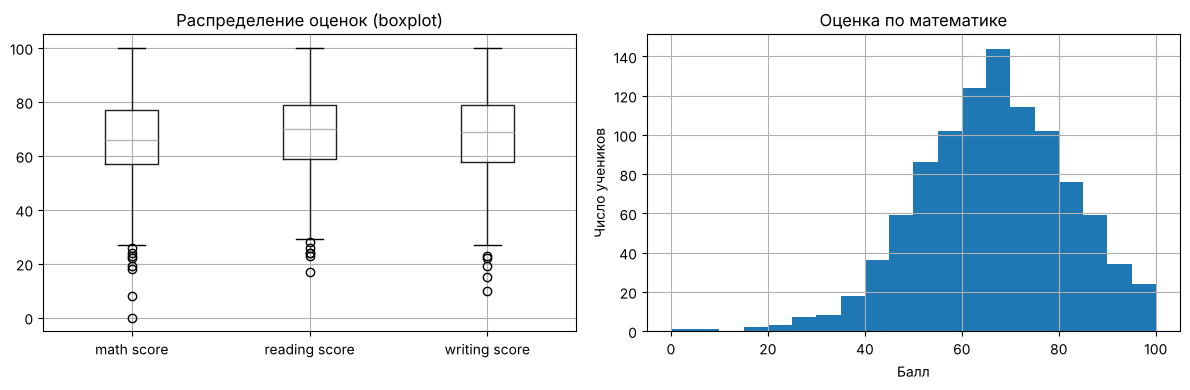

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_raw[score_cols].boxplot(ax=axes[0])
axes[0].set_title('Распределение оценок (boxplot)')

df_raw['math score'].hist(bins=20, ax=axes[1])
axes[1].set_title('Оценка по математике')
axes[1].set_xlabel('Балл')
axes[1].set_ylabel('Число учеников')

plt.tight_layout()
plt.show()

In [16]:
# отдельно смотрим на самую низкую оценку - math score = 0
df_raw[df_raw['math score'] == 0]

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
59,female,group C,some high school,free/reduced,none,0,17,10


**Итог:**
- нарушений диапазона нет - все оценки в пределах 0-100;
- выбросы по IQR есть только снизу (8 в математике, 6 в чтении, 5 в письме) - это очень низкие баллы;
- самый подозрительный случай - **math score = 0** у одной ученицы. Но у неё же очень низкие оценки по чтению (17) и письму (10), то есть результат согласуется с остальными - это похоже на реальный очень слабый результат, а не на сбой (например, сбой выглядел бы как 0 по математике при 90 по чтению).

**Решение:** выбросы не удаляем - статистическая редкость сама по себе не подтверждает ошибку. Сохраняем их и помечаем флагом, чтобы на этапе моделирования можно было проверить их влияние.

## 8. Согласованность

Проверяем, выполняются ли общие правила между связанными полями. Жёстких зависимостей (как «дата выписки после даты поступления») в датасете нет, но есть логичное ожидание: три оценки одного ученика связаны между собой. Проверим:
1. корреляцию между оценками;
2. записи с очень большим разрывом между оценками (больше 25 баллов) - такие сочетания подозрительны.

In [17]:
df_raw[score_cols].corr().round(3)

,math score,reading score,writing score
math score,1.000,0.818,0.803
reading score,0.818,1.000,0.955
writing score,0.803,0.955,1.000


In [18]:
gap_mr = (df_raw['math score'] - df_raw['reading score']).abs()
gap_rw = (df_raw['reading score'] - df_raw['writing score']).abs()

print('Разрыв математика-чтение > 25:', (gap_mr > 25).sum())
print('Разрыв чтение-письмо > 25:', (gap_rw > 25).sum())

df_raw[gap_mr > 25]

Разрыв математика-чтение > 25: 3
Разрыв чтение-письмо > 25: 0


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
371,female,group C,some college,free/reduced,completed,45,73,70
423,female,group A,some high school,standard,completed,59,85,80
620,female,group C,high school,free/reduced,none,35,61,54


**Итог:** оценки сильно связаны между собой (корреляция 0.80-0.95), чтение и письмо - особенно сильно (0.95). Записей с разрывом больше 25 баллов всего 3 из 1000, они правдоподобны (ученик может хорошо читать и плохо решать математику), поэтому противоречий нет.

Важный вывод для моделирования: из-за высокой корреляции reading score и writing score почти дублируют друг друга - это риск мультиколлинеарности, отмеченный в Этапе 1.

## 9. Баланс классов

Целевая переменная - math score (число), задача - регрессия. В Этапе 1 указан вариант перевода в классификацию «сдал / не сдал» по порогу 60 баллов. Проверим баланс классов для этого варианта, а также размеры групп по признакам - маленькие группы дают менее надёжные выводы.

In [19]:
df_raw['pass_math'] = (df_raw['math score'] >= 60).astype(int)

balance = df_raw['pass_math'].value_counts().rename({1: 'Сдал (>= 60)', 0: 'Не сдал (< 60)'})
balance_share = (df_raw['pass_math'].value_counts(normalize=True) * 100).round(1)
balance_share.index = balance.index

pd.DataFrame({'Учеников': balance, 'Доля, %': balance_share})

,Учеников,"Доля, %"
pass_math,,
Сдал (>= 60),677,67.7
Не сдал (< 60),323,32.3


In [20]:
for col in cat_cols:
    share = (df_raw[col].value_counts(normalize=True) * 100).round(1)
    print(col)
    print(share.to_string())
    print()

gender
gender
female    51.8
male      48.2

race/ethnicity
race/ethnicity
group C    31.9
group D    26.2
group B    19.0
group E    14.0
group A     8.9

parental level of education
parental level of education
some college          22.6
associate's degree    22.2
high school           19.6
some high school      17.9
bachelor's degree     11.8
master's degree        5.9

lunch
lunch
standard        64.5
free/reduced    35.5

test preparation course
test preparation course
none         64.2
completed    35.8



**Итог:** соотношение классов 67.7% / 32.3% - умеренный дисбаланс. Модель, которая всем ставит «сдал», получит accuracy 67.7%, но не найдёт ни одного несдавшего - поэтому при классификации нужно смотреть precision и recall, а при разбиении на train/test - сохранять доли классов (stratify).

Самые маленькие группы: `group A` (8.9%) и `master's degree` (5.9%, всего 59 учеников) - выводы по ним менее надёжны.

## 10. Профиль качества

Сводная таблица всех проверок: число нарушений, база (от чего считаем) и доля. Нарушения могут пересекаться, поэтому проценты нельзя складывать.

In [21]:
n = len(df_raw)

checks = []
checks.append(['Пропуски (все столбцы)', df_raw.drop(columns='pass_math').isna().sum().sum(), n * 8, 'ячеек'])
checks.append(['Особые маркеры пропуска', sum(df_raw[c].astype(str).str.strip().isin(markers).sum() for c in cat_cols), n * 5, 'ячеек'])
checks.append(['Неверный формат оценок', sum(pd.to_numeric(df_raw[c], errors='coerce').isna().sum() for c in score_cols), n * 3, 'ячеек'])
checks.append(['Разночтения в категориях', sum(df_raw[c].nunique() - df_raw[c].str.strip().str.lower().nunique() for c in cat_cols), 5, 'столбцов'])
checks.append(['Полные повторы сверх первой строки', df_raw.drop(columns='pass_math').duplicated().sum(), n, 'строк'])
checks.append(['Оценки вне 0-100', sum(((df_raw[c] < 0) | (df_raw[c] > 100)).sum() for c in score_cols), n * 3, 'ячеек'])

for col in score_cols:
    q1, q3 = df_raw[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    cnt = ((df_raw[col] < q1 - 1.5 * iqr) | (df_raw[col] > q3 + 1.5 * iqr)).sum()
    checks.append([f'Выбросы IQR: {col}', cnt, n, 'строк'])

checks.append(['Разрыв математика-чтение > 25', (gap_mr > 25).sum(), n, 'строк'])

profile = pd.DataFrame(checks, columns=['Проверка', 'Нарушений', 'База', 'Единица'])
profile['Доля, %'] = (profile['Нарушений'] / profile['База'] * 100).round(1)
profile

,Проверка,Нарушений,База,Единица,"Доля, %"
0,Пропуски (все столбцы),0,8000,ячеек,0.0
1,Особые маркеры пропуска,0,5000,ячеек,0.0
2,Неверный формат оценок,0,3000,ячеек,0.0
3,Разночтения в категориях,0,5,столбцов,0.0
4,Полные повторы сверх первой строки,0,1000,строк,0.0
5,Оценки вне 0-100,0,3000,ячеек,0.0
6,Выбросы IQR: math score,8,1000,строк,0.8
7,Выбросы IQR: reading score,6,1000,строк,0.6
8,Выбросы IQR: writing score,5,1000,строк,0.5
9,Разрыв математика-чтение > 25,3,1000,строк,0.3


## 11. Приоритеты и решение по данным

| Приоритет | Что нашли | Решение |
|---|---|---|
| Блокирует расчёт | Ничего - пропусков, дублей и ошибок формата нет | - |
| Требует уточнения | Разделитель `;` вместо `,` после Excel | Чтение с автоопределением разделителя, сохранение чистого файла с `,` |
| Требует уточнения | math score = 0 у одной ученицы | Сверка с другими оценками: согласуется (17 и 10) - оставляем как реальное значение |
| Допустимо с условием | Выбросы снизу по IQR (5-8 на столбец) | Сохраняем, ставим флаг `is_outlier`, проверяем влияние при моделировании |
| Допустимо с условием | Сильная корреляция reading и writing (0.95) | Учитываем при выборе признаков модели |
| Допустимо с условием | Дисбаланс классов 68/32 (при пороге 60) | Метрики precision/recall, stratify при разбиении |
| Допустимо с условием | Маленькие группы (group A, master's degree) | Указываем меньшую надёжность выводов по ним |

## 12. Подготовка данных

Что делаем:
1. Переименовываем столбцы в удобный вид (без пробелов и `/`), чтобы с ними было проще работать в коде.
2. Переводим категориальные признаки в тип `category`, образование родителей - в упорядоченную категорию (от низшего уровня к высшему).
3. Добавляем средний балл `avg_score` (может пригодиться как альтернативная целевая переменная).
4. Добавляем целевую метку `pass_math` (сдал / не сдал по порогу 60) и флаг выброса `is_outlier`.
5. Сохраняем результат в отдельный файл - исходный файл не меняем.

In [22]:
df = df_raw.drop(columns='pass_math').copy()

df = df.rename(columns={
    'gender': 'gender',
    'race/ethnicity': 'race_ethnicity',
    'parental level of education': 'parent_education',
    'lunch': 'lunch',
    'test preparation course': 'test_prep',
    'math score': 'math_score',
    'reading score': 'reading_score',
    'writing score': 'writing_score'
})

for col in ['gender', 'race_ethnicity', 'lunch', 'test_prep']:
    df[col] = df[col].str.strip().astype('category')

edu_order = ['some high school', 'high school', 'some college',
             "associate's degree", "bachelor's degree", "master's degree"]
df['parent_education'] = pd.Categorical(df['parent_education'], categories=edu_order, ordered=True)

df['avg_score'] = df[['math_score', 'reading_score', 'writing_score']].mean(axis=1).round(2)
df['pass_math'] = (df['math_score'] >= 60).astype(int)

new_scores = ['math_score', 'reading_score', 'writing_score']
df['is_outlier'] = 0
for col in new_scores:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)
    df.loc[mask, 'is_outlier'] = 1

print(df.dtypes)
print()
print('Строк с флагом выброса:', df['is_outlier'].sum())
df.head()

gender              category
race_ethnicity      category
parent_education    category
lunch               category
test_prep           category
math_score             int64
reading_score          int64
writing_score          int64
avg_score            float64
pass_math              int64
is_outlier             int64
dtype: object

Строк с флагом выброса: 12


,gender,race_ethnicity,parent_education,lunch,test_prep,math_score,reading_score,writing_score,avg_score,pass_math,is_outlier
0,female,group B,bachelor's degree,standard,none,72,72,74,72.67,1,0
1,female,group C,some college,standard,completed,69,90,88,82.33,1,0
2,female,group B,master's degree,standard,none,90,95,93,92.67,1,0
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.33,0,0
4,male,group C,some college,standard,none,76,78,75,76.33,1,0


**Повторный аудит.** По правилу «повторяемого аудита» прогоняем основные проверки ещё раз уже на подготовленных данных - число строк не изменилось, пропусков и дублей не появилось.

In [23]:
print('Строк было / стало:', len(df_raw), '/', len(df))
print('Пропусков:', df.isna().sum().sum())
print('Полных дублей:', df.duplicated().sum())
print('Оценки вне 0-100:', ((df[new_scores] < 0) | (df[new_scores] > 100)).sum().sum())

Строк было / стало: 1000 / 1000
Пропусков: 0
Полных дублей: 0
Оценки вне 0-100: 0


In [24]:
CLEAN_PATH = '../data/processed/students_clean.csv'

# в Colab папки data нет - тогда сохраняем рядом с ноутбуком
if not os.path.exists('../data/processed'):
    CLEAN_PATH = 'students_clean.csv'

df.to_csv(CLEAN_PATH, index=False)
print('Сохранено:', CLEAN_PATH)

Сохранено: ../data/processed/students_clean.csv


## 13. Вывод

1. **Качество данных высокое:** нет пропусков, дубликатов, ошибок формата и значений вне допустимого диапазона 0-100. Категории записаны единообразно.
2. **Найденные особенности:** разделитель `;` после пересохранения в Excel, небольшое число низких выбросов (в том числе math score = 0), сильная связь между оценками (особенно чтение-письмо, 0.95), умеренный дисбаланс при классификации по порогу 60 (68/32), маленькие группы `group A` и `master's degree`.
3. **Что сделано:** выбросы сохранены и помечены флагом, категории переведены в нужный тип, образование родителей - в упорядоченную шкалу, добавлены `avg_score`, `pass_math` и `is_outlier`. Исходный файл не изменён, чистая версия сохранена в `data/processed/students_clean.csv`.
4. **Ограничение, которое аудит не может снять:** датасет, вероятно, синтетический, а этническая группа закодирована анонимно - это ограничивает перенос выводов на реальных учеников.

**Решение:** данные пригодны для задачи из Этапа 1 и готовы к следующему этапу - разведочному анализу и построению модели.